In [1]:
import os
import h5py
import requests
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive,userdata
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
os.chdir("/content/drive/MyDrive/TNGdata")

In [3]:
baseUrl = 'http://www.tng-project.org/api/'
headers = {"api-key":userdata.get("TNG_API_KEY")}

In [5]:
def get(path, params=None):
    # make HTTP GET request to path
    r = requests.get(path, params=params, headers=headers)

    # raise exception if response code is not HTTP SUCCESS (200)
    r.raise_for_status()

    if r.headers['content-type'] == 'application/json':
        return r.json() # parse json responses automatically

    if 'content-disposition' in r.headers:
        filename = r.headers['content-disposition'].split("filename=")[1]
        with open(filename, 'wb') as f:
            f.write(r.content)
        return filename # return the filename string

    return r

In [6]:
r = get(baseUrl)

In [7]:
tng50d1 = get(baseUrl + "TNG50-1")
subhalo50d1_cutout = get(tng50d1['url'] + "/snapshots/33/subhalos/0/cutout.hdf5", {"gas":"Coordinates,Masses,MagneticField"})

In [8]:
with h5py.File(subhalo50d1_cutout,'r') as f:
  x = f['PartType0']['Coordinates'][:,0] # subtract off subhalo position if you like
  y = f['PartType0']['Coordinates'][:,1]
  dens = np.log10(f['PartType0']['Masses'][:])
  header = dict(f['Header'].attrs)

In [9]:
with h5py.File(subhalo50d1_cutout,'r') as f:
  x = f['PartType0']['Coordinates'][:,0] # subtract off subhalo position if you like
  y = f['PartType0']['Coordinates'][:,1]
  mag = f['PartType0']['MagneticField'][:]

In [10]:
print(header.keys())

dict_keys(['BoxSize', 'CutoutID', 'CutoutRequest', 'CutoutType', 'Git_commit', 'Git_date', 'HubbleParam', 'MassTable', 'NumFilesPerSnapshot', 'NumPart_ThisFile', 'Omega0', 'OmegaBaryon', 'OmegaLambda', 'Redshift', 'SimulationName', 'SnapshotNumber', 'Time', 'UnitLength_in_cm', 'UnitMass_in_g', 'UnitVelocity_in_cm_per_s'])


In [11]:
scale_factor = 1.0 / (1.0 + header["Redshift"])
hubble_param = header['HubbleParam']
mag_physical = mag * hubble_param / scale_factor**2 * 2.6e-6 # https://www.tng-project.org/data/docs/specifications/

In [12]:
hubble_param

np.float64(0.6774)

In [13]:
x.shape, y.shape, mag_physical.shape

((22388757,), (22388757,), (22388757, 3))

In [14]:
mag_physical_magnitude = np.sqrt(mag_physical[:,0]**2 + mag_physical[:,1]**2 + mag_physical[:,2]**2)

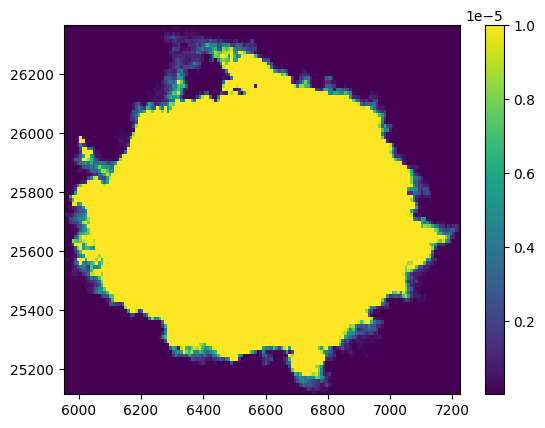

In [15]:
plt.hist2d(x,y,weights=mag_physical_magnitude,bins=[150,100], vmin=1e-8, vmax=1e-5)
plt.colorbar()
plt.savefig("figure1_bfield.png", dpi=300)

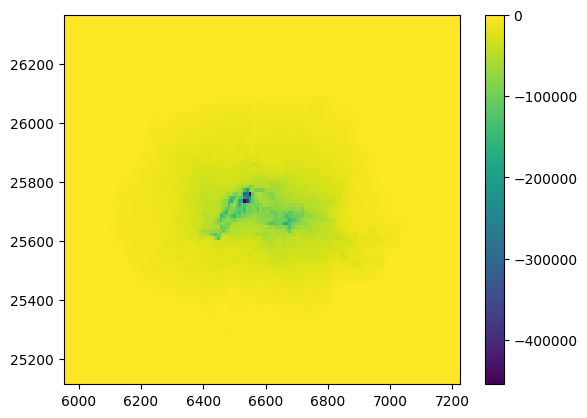

In [16]:
plt.hist2d(x,y,weights=dens,bins=[150,100])
plt.colorbar()
plt.savefig("figure1_density.png", dpi=300)

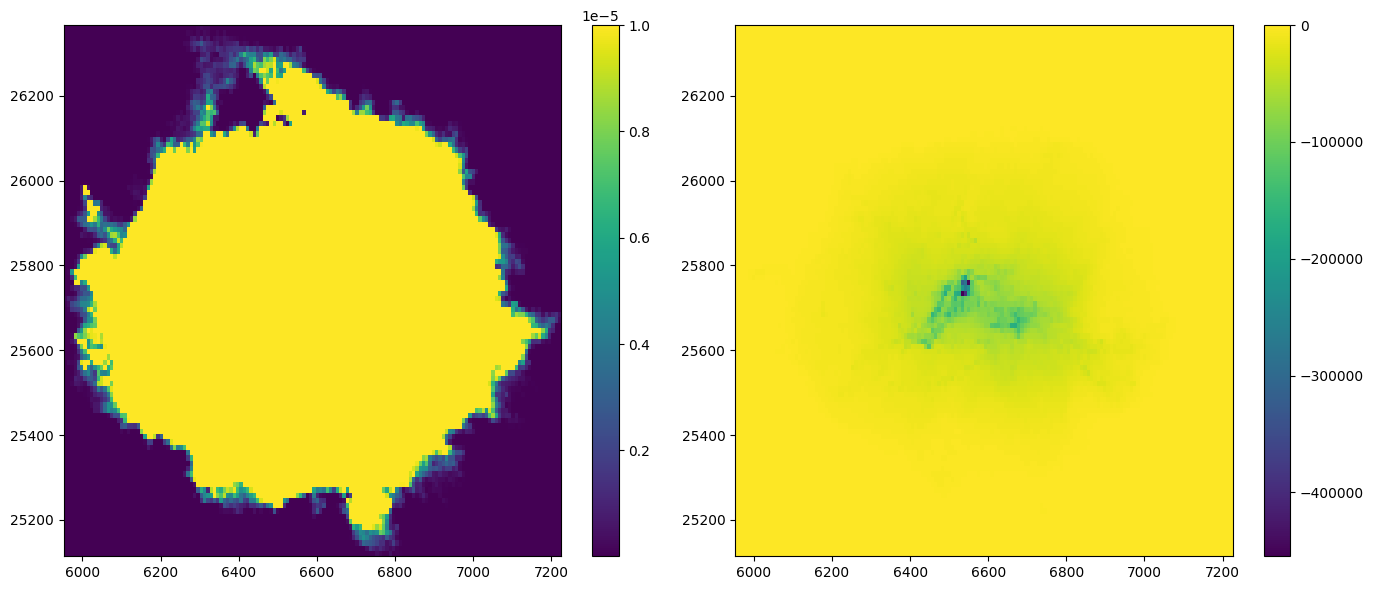

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

im1 = ax1.hist2d(x, y, weights=mag_physical_magnitude, bins=[150, 100], vmin=1e-8, vmax=1e-5)
fig.colorbar(im1[3], ax=ax1)

im2 = ax2.hist2d(x, y, weights=dens, bins=[150, 100])
fig.colorbar(im2[3], ax=ax2)

plt.tight_layout()
plt.savefig("magXdens.png", dpi=300)
plt.show()

In [18]:
np.median(mag_physical_magnitude), np.mean(mag_physical_magnitude), np.min(mag_physical_magnitude), np.max(mag_physical_magnitude)

(np.float64(1.1527387881547284e-06),
 np.float64(5.783799698862082e-06),
 np.float64(2.213209775147987e-12),
 np.float64(0.00793010384266847))

In [19]:
subhalo50d1 = get(tng50d1['url'] + "/snapshots/33/subhalos/0")
subhalo50d1

{'snap': 33,
 'id': 0,
 'bhmdot': 0.00049766,
 'cm_x': 6578.67,
 'cm_y': 25717.4,
 'cm_z': 24445.4,
 'gasmetallicity': 0.0185783,
 'gasmetallicityhalfrad': 0.0224876,
 'gasmetallicitymaxrad': 0.0287907,
 'gasmetallicitysfr': 0.00951917,
 'gasmetallicitysfrweighted': 0.0199592,
 'pos_x': 6537.03,
 'pos_y': 25737.2,
 'pos_z': 24461.2,
 'halfmassrad': 242.579,
 'halfmassrad_gas': 266.689,
 'halfmassrad_dm': 244.781,
 'halfmassrad_stars': 6.5854,
 'halfmassrad_bhs': 0.0,
 'len': 69439857,
 'len_gas': 22388757,
 'len_dm': 39076415,
 'len_stars': 7974683,
 'len_bhs': 2,
 'mass': 1373.54,
 'mass_gas': 136.162,
 'mass_dm': 1201.08,
 'mass_stars': 36.256,
 'mass_bhs': 0.040295,
 'massinhalfrad': 25.323,
 'massinhalfrad_gas': 0.637884,
 'massinhalfrad_dm': 6.51696,
 'massinhalfrad_stars': 18.128,
 'massinhalfrad_bhs': 0.040151,
 'massinmaxrad': 9.82609,
 'massinmaxrad_gas': 0.003535,
 'massinmaxrad_dm': 0.882238,
 'massinmaxrad_stars': 8.90017,
 'massinmaxrad_bhs': 0.040151,
 'massinrad': 37.091

In [20]:
sfr = subhalo50d1['sfr']
bhmdot = subhalo50d1['bhmdot']
mstar = subhalo50d1['mass_stars']
mhalo = subhalo50d1['mass_log_msun']

In [23]:
# The Loop!
resolutions = ["1"]
num_subhalos = 1000

fields = ['sfr', 'bhmdot', 'mass_stars', "mass_bhs", 'mass_log_msun']

# extra 2 = mean, median magnetic field
data = np.zeros((num_subhalos, len(resolutions), len(fields)+2)) -1

for j,resolution in enumerate(resolutions):
  print("j: ", j)
  subhalos = get(baseUrl + "TNG50-" + resolution + f"/snapshots/33/subhalos/", {"limit":100, "order_by": "-mass_stars"})

  valid_subhalos = 0
  i = -1
  while valid_subhalos < num_subhalos:
    i += 1
    print("i: ", i)

    if i >= 100:
      subhalos = get(subhalos["next"])
      i = 0

    try:
      subhalo = get(subhalos["results"][i]["url"]) #get(baseUrl + "TNG50-" + resolution + f"/snapshots/33/subhalos/{i}/")
    except:
      continue

    if subhalo['subhaloflag'] != 1:
      print("i,j, primary flag, subhaloflag: ", i,j, subhalo['primary_flag'], subhalo['subhaloflag'])
      continue

    for k,field in enumerate(fields):
      value = subhalo[field]
      if field == "mass_log_msun":
        value = 10**value

      if field in ["mass_stars", "mass_bhs"]:
        value *= 1e10 / hubble_param

      if field == "bhmdot":
        value *= 1e10 / 1e9 # code-mass conversion, multiply by 1e10/h; code-time is 1 Gyr/h

      data[i, j, k] = value

    subhalo_cutout = get(subhalo['cutouts']['subhalo'], {"gas":"Coordinates,MagneticField"})
    with h5py.File(subhalo_cutout,'r') as f:
      try:
        mag = f['PartType0']['MagneticField'][:]
      except KeyError:
        print("error for subhalo i and resolution j: ", i, j)
        continue
      header = dict(f['Header'].attrs)
    scale_factor = 1.0 / (1.0 + header["Redshift"])
    hubble_param = header['HubbleParam']
    mag_physical = mag * hubble_param / scale_factor**2 * 2.6e-6 # https://www.tng-project.org/data/docs/specifications/
    mag_physical_norm = np.sqrt(mag_physical[:,0]**2 + mag_physical[:,1]**2 + mag_physical[:,2]**2)
    data[i, j, -2] = np.mean(mag_physical_norm)
    data[i, j, -1] = np.median(mag_physical_norm)
    print(f"Processed subhalo {i}")

    np.savez_compressed("subhalo_data_with_bhmasses.npz", data=data)

j:  0
i:  0
Processed subhalo 0
i:  1
Processed subhalo 1
i:  2
Processed subhalo 2
i:  3
Processed subhalo 3
i:  4
Processed subhalo 4
i:  5
Processed subhalo 5
i:  6
Processed subhalo 6
i:  7
Processed subhalo 7
i:  8
Processed subhalo 8
i:  9
Processed subhalo 9
i:  10
Processed subhalo 10
i:  11
Processed subhalo 11
i:  12
Processed subhalo 12
i:  13
Processed subhalo 13
i:  14
Processed subhalo 14
i:  15
Processed subhalo 15
i:  16
Processed subhalo 16
i:  17
Processed subhalo 17
i:  18
Processed subhalo 18
i:  19
Processed subhalo 19
i:  20
Processed subhalo 20
i:  21
Processed subhalo 21
i:  22
Processed subhalo 22
i:  23
Processed subhalo 23
i:  24
Processed subhalo 24
i:  25
Processed subhalo 25
i:  26
Processed subhalo 26
i:  27
Processed subhalo 27
i:  28
Processed subhalo 28
i:  29
Processed subhalo 29
i:  30
Processed subhalo 30
i:  31
Processed subhalo 31
i:  32
Processed subhalo 32
i:  33
Processed subhalo 33
i:  34
Processed subhalo 34
i:  35
Processed subhalo 35
i:  36

HTTPError: 403 Client Error: Forbidden for url: https://data-eu.tng-project.org/cutout/subhalo/L35n2160TNG/33/117098/16386.0.0.0.0.0/?token=c9ebec17fdeaab106fdc

In [24]:
data = np.load("subhalo_data_with_bhmasses.npz")
data = data["data"]

sfrs = data[:,0,0]
bhmdots = data[:,0,1]
mass_stars = data[:,0,2]
mass_bhmdots = data[:,0,3]
mass_log_msun = data[:,0,4]

normalized_sfrs = sfrs / mass_stars
normalized_bhmdots = bhmdots / mass_bhmdots

/tmp/ipykernel_658/1313167293.py:11: RuntimeWarning: invalid value encountered in divide
  normalized_bhmdots = bhmdots / mass_bhmdots


/tmp/ipykernel_658/2047169732.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([clean_norm_sfrs, clean_norm_bhmdots], labels=['SFR', '$\\dot{M}_{BH}$'])


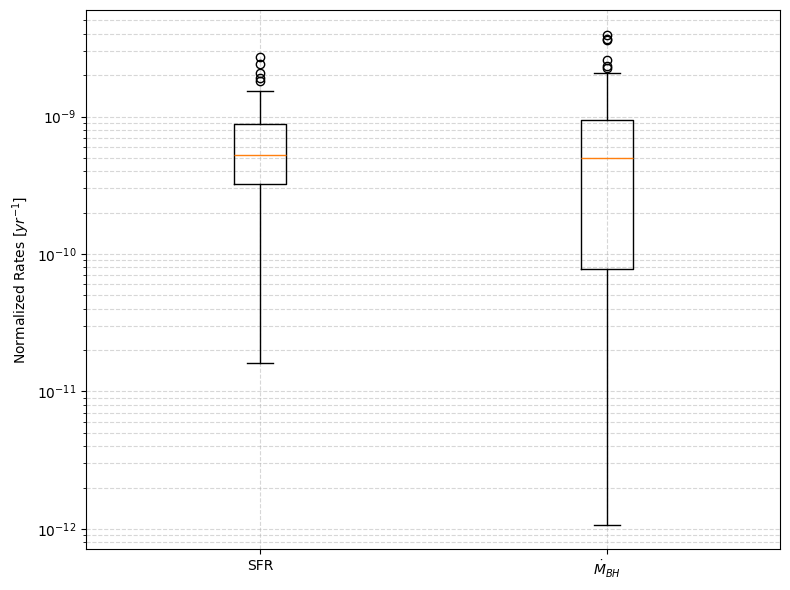

In [28]:
valid_mask = (sfrs >= 0) & (bhmdots >= 0) & (mass_stars > 0) & (mass_bhmdots > 0)

clean_norm_sfrs = normalized_sfrs[valid_mask]
clean_norm_bhmdots = normalized_bhmdots[valid_mask]

plt.figure(figsize=(8, 6))
plt.boxplot([clean_norm_sfrs, clean_norm_bhmdots], labels=['SFR', '$\\dot{M}_{BH}$'])
plt.yscale('log')
plt.ylabel('Normalized Rates [$yr^{-1}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("SFR&Bhmdotbox.png", dpi=300)
plt.show()

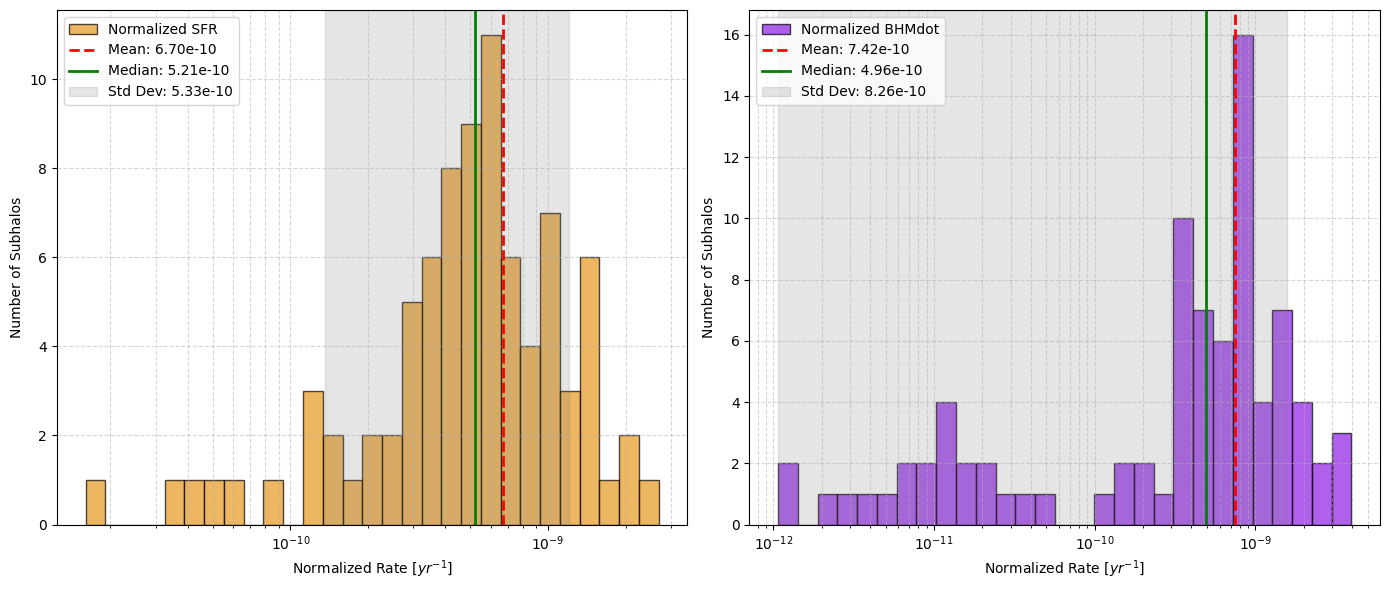

In [44]:
stats = {
    'Normalized SFR': {
        'data': clean_norm_sfrs,
        'mean': np.mean(clean_norm_sfrs),
        'median': np.median(clean_norm_sfrs),
        'std': np.std(clean_norm_sfrs)
    },
    'Normalized BHMdot': {
        'data': clean_norm_bhmdots,
        'mean': np.mean(clean_norm_bhmdots),
        'median': np.median(clean_norm_bhmdots),
        'std': np.std(clean_norm_bhmdots)
    }
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#e6981c', '#8e1ce6']

for ax, color, (label, s_data) in zip(axes, colors, stats.items()):
    bins = np.logspace(np.log10(s_data['data'].min()), np.log10(s_data['data'].max()), 30)

    ax.hist(s_data['data'], bins=bins, color=color, alpha=0.7, edgecolor='black', label=label)

    ax.axvline(s_data['mean'], color='red', linestyle='--', linewidth=2, label=f"Mean: {s_data['mean']:.2e}")
    ax.axvline(s_data['median'], color='green', linestyle='-', linewidth=2, label=f"Median: {s_data['median']:.2e}")

    ax.axvspan(max(s_data['data'].min(), s_data['mean'] - s_data['std']),
               s_data['mean'] + s_data['std'],
               color='gray', alpha=0.2, label=f"Std Dev: {s_data['std']:.2e}")

    ax.set_xscale('log')
    ax.set_xlabel('Normalized Rate [$yr^{-1}$]')
    ax.set_ylabel('Number of Subhalos')

    ax.legend()
    ax.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("SFR_BHMdot_histograms.png", dpi=300)
plt.show()

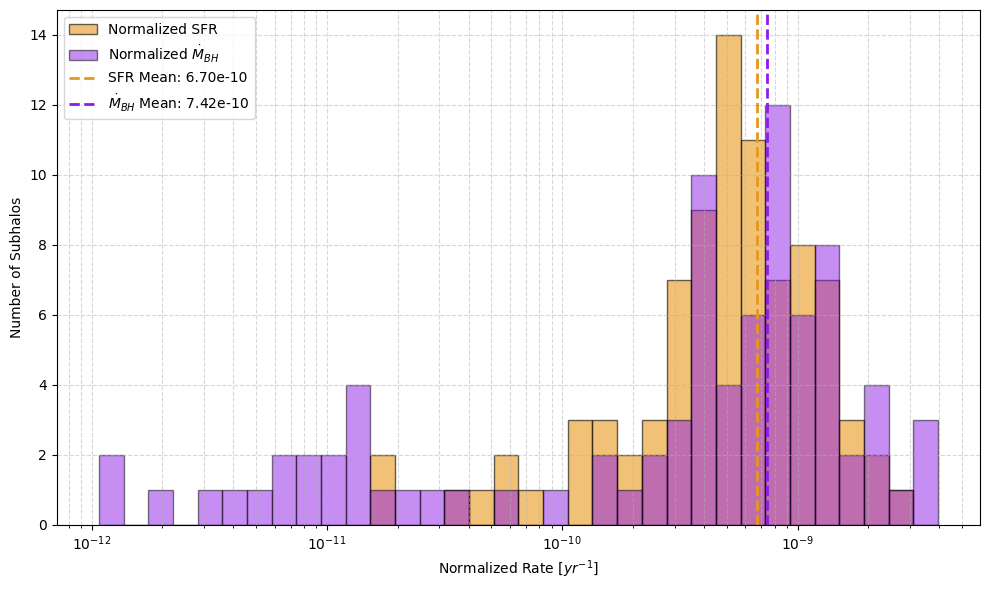

In [45]:
min_val = min(clean_norm_sfrs.min(), clean_norm_bhmdots.min())
max_val = max(clean_norm_sfrs.max(), clean_norm_bhmdots.max())
bins = np.logspace(np.log10(min_val), np.log10(max_val), 35)

plt.figure(figsize=(10, 6))

plt.hist(clean_norm_sfrs, bins=bins, color='#e6981c', alpha=0.6, edgecolor='black', label='Normalized SFR')
plt.hist(clean_norm_bhmdots, bins=bins, color='#8e1ce6', alpha=0.5, edgecolor='black', label='Normalized $\\dot{M}_{BH}$')

plt.axvline(np.mean(clean_norm_sfrs), color='#e6981c', linestyle='--', linewidth=2, label=f"SFR Mean: {np.mean(clean_norm_sfrs):.2e}")
plt.axvline(np.mean(clean_norm_bhmdots), color='#8e1ce6', linestyle='--', linewidth=2, label=f"$\\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_norm_bhmdots):.2e}")

plt.xscale('log')
plt.xlabel('Normalized Rate [$yr^{-1}$]')
plt.ylabel('Number of Subhalos')
plt.legend(loc='upper left')
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("SFR_BHMdot_overlapping_histogram.png", dpi=300)
plt.show()

### Part 1: Visualizations of Actual (Unnormalized) SFR and $\dot{M}_{\text{BH}}$

- **Star Formation Rate (SFR)** in units of $[\text{M}_{\odot} \, \text{yr}^{-1}]$
- **Black Hole Accretion Rate ($\dot{M}_{\text{BH}}$)** in units of $[\text{M}_{\odot} \, \text{yr}^{-1}]$

<>:5: SyntaxWarning: invalid escape sequence '\d'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\d'
<>:7: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_658/3665824039.py:5: SyntaxWarning: invalid escape sequence '\d'
  plt.boxplot([clean_sfrs, clean_bhmdots], tick_labels=['SFR', '$\dot{M}_{BH}$'])
/tmp/ipykernel_658/3665824039.py:7: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('Actual Rates [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')


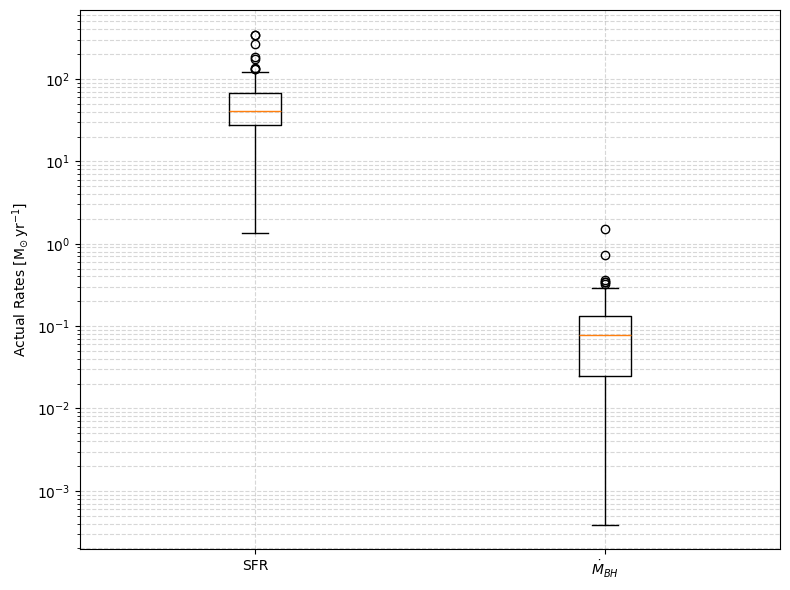

In [32]:
clean_sfrs = sfrs[valid_mask]
clean_bhmdots = bhmdots[valid_mask]

plt.figure(figsize=(8, 6))
plt.boxplot([clean_sfrs, clean_bhmdots], tick_labels=['SFR', '$\dot{M}_{BH}$'])
plt.yscale('log')
plt.ylabel('Actual Rates [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("actual_rates_boxplot.png", dpi=300)
plt.show()

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_658/3633809638.py:30: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel('Actual Rate [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')


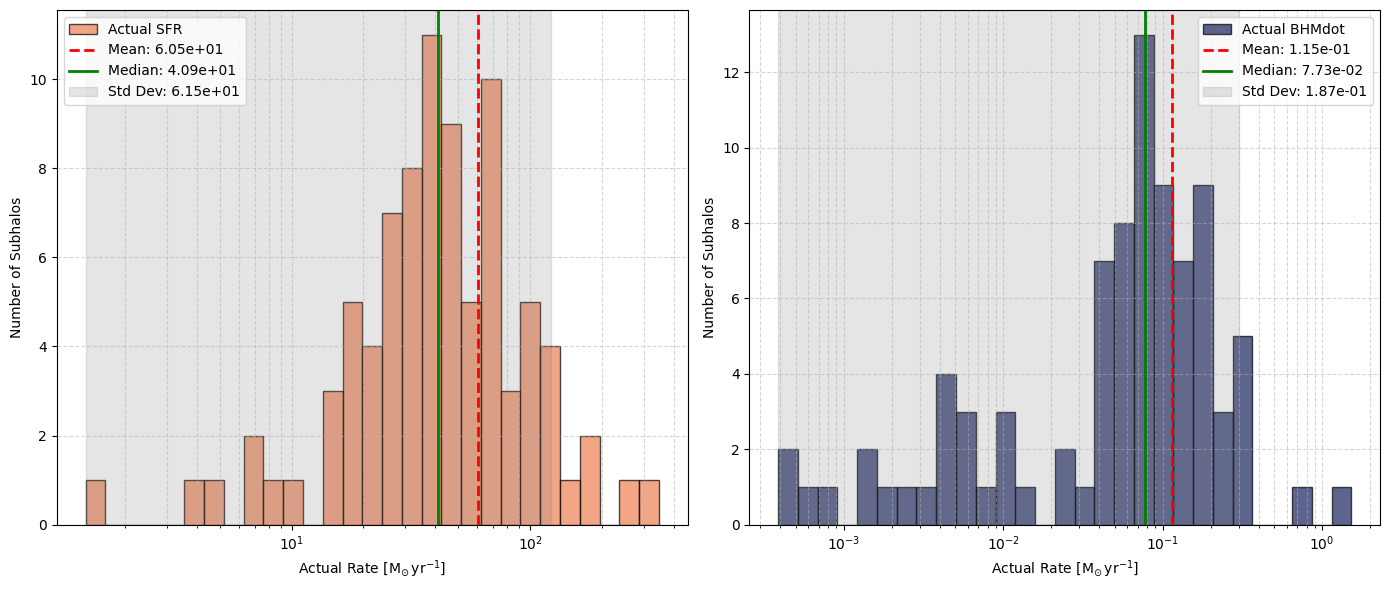

In [46]:
actual_stats = {
    'Actual SFR': {
        'data': clean_sfrs,
        'mean': np.mean(clean_sfrs),
        'median': np.median(clean_sfrs),
        'std': np.std(clean_sfrs)
    },
    'Actual BHMdot': {
        'data': clean_bhmdots,
        'mean': np.mean(clean_bhmdots),
        'median': np.median(clean_bhmdots),
        'std': np.std(clean_bhmdots)
    }
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#ed8153', '#18235e']

for ax, color, (label, s_data) in zip(axes, colors, actual_stats.items()):
    bins = np.logspace(np.log10(s_data['data'].min()), np.log10(s_data['data'].max()), 30)

    ax.hist(s_data['data'], bins=bins, color=color, alpha=0.7, edgecolor='black', label=label)
    ax.axvline(s_data['mean'], color='red', linestyle='--', linewidth=2, label=f"Mean: {s_data['mean']:.2e}")
    ax.axvline(s_data['median'], color='green', linestyle='-', linewidth=2, label=f"Median: {s_data['median']:.2e}")
    ax.axvspan(max(s_data['data'].min(), s_data['mean'] - s_data['std']),
               s_data['mean'] + s_data['std'],
               color='gray', alpha=0.2, label=f"Std Dev: {s_data['std']:.2e}")

    ax.set_xscale('log')
    ax.set_xlabel('Actual Rate [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')
    ax.set_ylabel('Number of Subhalos')
    ax.legend()
    ax.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("actual_rates_side_by_side.png", dpi=300)
plt.show()

<>:7: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_658/4290175656.py:7: SyntaxWarning: invalid escape sequence '\d'
  plt.hist(clean_bhmdots, bins=bins, color='#18235e', alpha=0.5, edgecolor='black', label='Actual $\dot{M}_{BH}$')
/tmp/ipykernel_658/4290175656.py:10: SyntaxWarning: invalid escape sequence '\d'
  plt.axvline(np.mean(clean_bhmdots), color='#18235e', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_bhmdots):.2e}")
/tmp/ipykernel_658/4290175656.py:13: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Actual Rate [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')


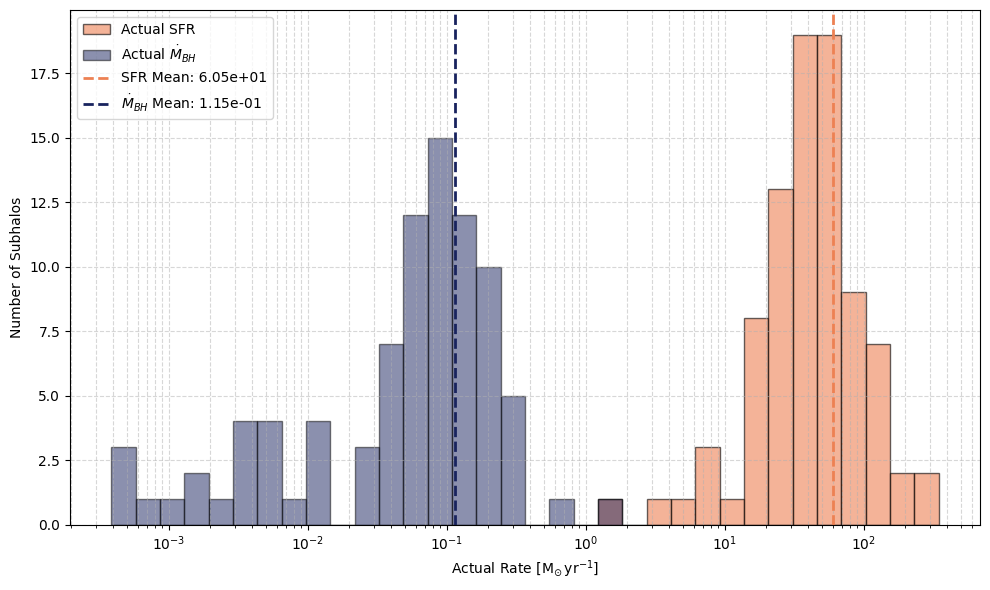

In [47]:
min_val = min(clean_sfrs.min(), clean_bhmdots.min())
max_val = max(clean_sfrs.max(), clean_bhmdots.max())
bins = np.logspace(np.log10(min_val), np.log10(max_val), 35)

plt.figure(figsize=(10, 6))
plt.hist(clean_sfrs, bins=bins, color='#ed8153', alpha=0.6, edgecolor='black', label='Actual SFR')
plt.hist(clean_bhmdots, bins=bins, color='#18235e', alpha=0.5, edgecolor='black', label='Actual $\dot{M}_{BH}$')

plt.axvline(np.mean(clean_sfrs), color='#ed8153', linestyle='--', linewidth=2, label=f"SFR Mean: {np.mean(clean_sfrs):.2e}")
plt.axvline(np.mean(clean_bhmdots), color='#18235e', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_bhmdots):.2e}")

plt.xscale('log')
plt.xlabel('Actual Rate [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')
plt.ylabel('Number of Subhalos')
plt.legend(loc='upper left')
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("actual_rates_overlapping.png", dpi=300)
plt.show()

### Part 2: Analysis of Stellar Mass ($M_{\star}$) and Black Hole Mass ($M_{\text{BH}}$)


In [37]:
clean_mstar = mass_stars[valid_mask]
clean_mbh = mass_bhmdots[valid_mask]

print("=== Stellar Mass (M_star) Statistics ===")
print(f"Mean:   {np.mean(clean_mstar):.2e} M_sun")
print(f"Median: {np.median(clean_mstar):.2e} M_sun")
print(f"Min:    {np.min(clean_mstar):.2e} M_sun")
print(f"Max:    {np.max(clean_mstar):.2e} M_sun\n")

print("=== Black Hole Mass (M_BH) Statistics ===")
print(f"Mean:   {np.mean(clean_mbh):.2e} M_sun")
print(f"Median: {np.median(clean_mbh):.2e} M_sun")
print(f"Min:    {np.min(clean_mbh):.2e} M_sun")
print(f"Max:    {np.max(clean_mbh):.2e} M_sun")

=== Stellar Mass (M_star) Statistics ===
Mean:   1.15e+11 M_sun
Median: 7.39e+10 M_sun
Min:    4.48e+10 M_sun
Max:    6.00e+11 M_sun

=== Black Hole Mass (M_BH) Statistics ===
Mean:   2.45e+08 M_sun
Median: 1.85e+08 M_sun
Min:    3.50e+07 M_sun
Max:    1.17e+09 M_sun


<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_658/3487039837.py:15: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('Stellar Mass $M_{\star}$ [$\mathrm{M}_{\odot}$]')
/tmp/ipykernel_658/3487039837.py:16: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('Black Hole Mass $M_{\text{BH}}$ [$\mathrm{M}_{\odot}$]')


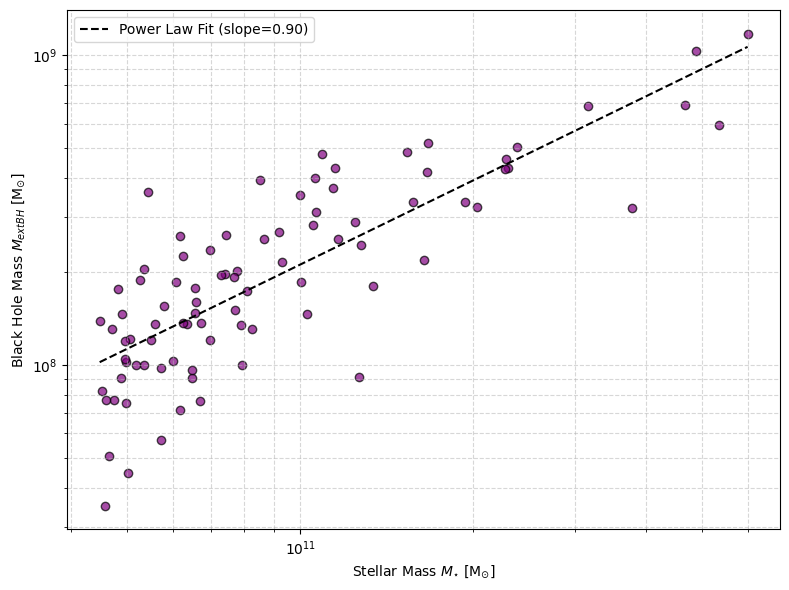

In [38]:
plt.figure(figsize=(8, 6))
plt.scatter(clean_mstar, clean_mbh, color='purple', alpha=0.7, edgecolors='k')

log_mstar = np.log10(clean_mstar)
log_mbh = np.log10(clean_mbh)
slope, intercept = np.polyfit(log_mstar, log_mbh, 1)

mstar_fit = np.logspace(np.log10(clean_mstar.min()), np.log10(clean_mstar.max()), 100)
bh_fit = 10**intercept * mstar_fit**slope

plt.plot(mstar_fit, bh_fit, color='black', linestyle='--', label=f'Power Law Fit (slope={slope:.2f})')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Stellar Mass $M_{\star}$ [$\mathrm{M}_{\odot}$]')
plt.ylabel('Black Hole Mass $M_{\text{BH}}$ [$\mathrm{M}_{\odot}$]')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("mass_scaling_relation.png", dpi=300)
plt.show()

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_658/3846408166.py:2: SyntaxWarning: invalid escape sequence '\s'
  plt.boxplot([clean_mstar, clean_mbh], tick_labels=['Stellar Mass ($M_{\star}$)', 'Black Hole Mass ($M_{\mathrm{BH}}$)'])
/tmp/ipykernel_658/3846408166.py:2: SyntaxWarning: invalid escape sequence '\m'
  plt.boxplot([clean_mstar, clean_mbh], tick_labels=['Stellar Mass ($M_{\star}$)', 'Black Hole Mass ($M_{\mathrm{BH}}$)'])
/tmp/ipykernel_658/3846408166.py:4: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('Mass [$\mathrm{M}_{\odot}$]')


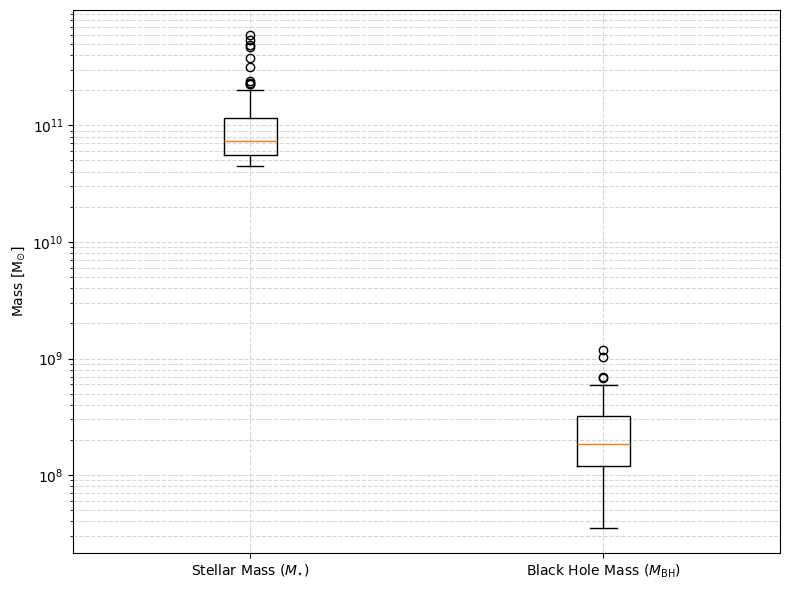

In [42]:
plt.figure(figsize=(8, 6))
plt.boxplot([clean_mstar, clean_mbh], tick_labels=['Stellar Mass ($M_{\star}$)', 'Black Hole Mass ($M_{\mathrm{BH}}$)'])
plt.yscale('log')
plt.ylabel('Mass [$\mathrm{M}_{\odot}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("masses_boxplot.png", dpi=300)
plt.show()

<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_658/1414796989.py:9: SyntaxWarning: invalid escape sequence '\s'
  axes[0].set_xlabel('Stellar Mass $M_{\star}$ [$\mathrm{M}_{\odot}$]')
/tmp/ipykernel_658/1414796989.py:20: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_xlabel('Black Hole Mass $M_{\mathrm{BH}}$ [$\mathrm{M}_{\odot}$]')


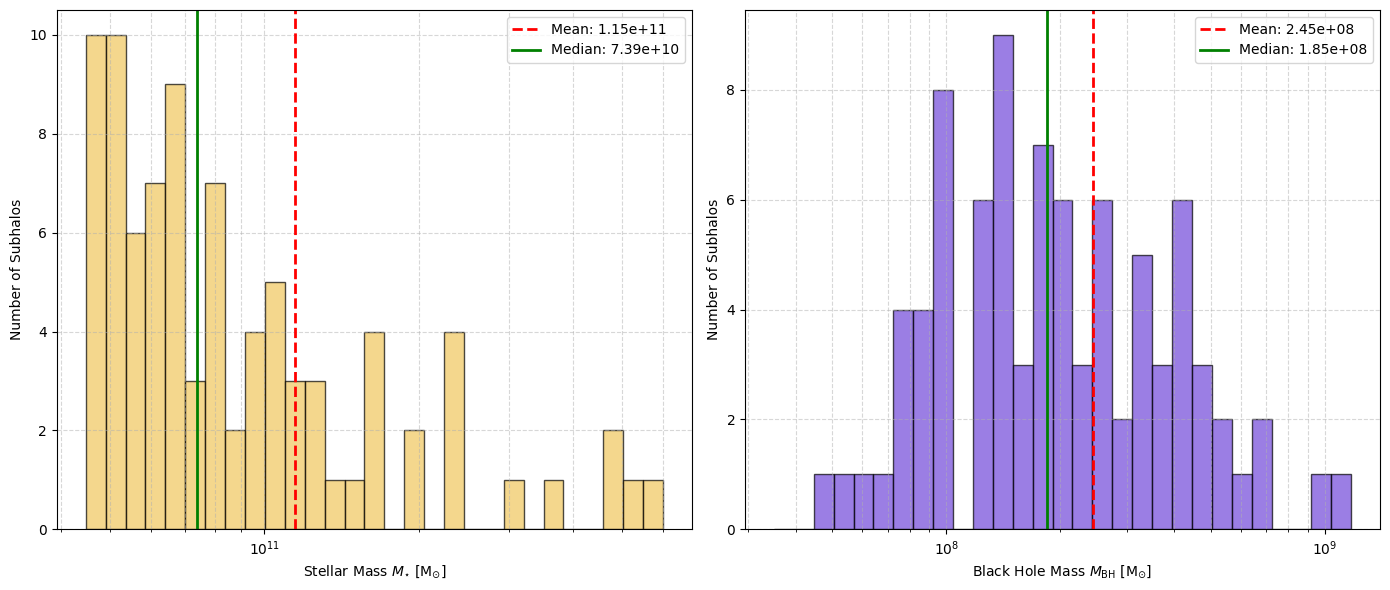

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Stellar Mass Histogram
bins_star = np.logspace(np.log10(clean_mstar.min()), np.log10(clean_mstar.max()), 30)
axes[0].hist(clean_mstar, bins=bins_star, color='#f0c65d', alpha=0.7, edgecolor='black')
axes[0].axvline(np.mean(clean_mstar), color='red', linestyle='--', linewidth=2, label=f"Mean: {np.mean(clean_mstar):.2e}")
axes[0].axvline(np.median(clean_mstar), color='green', linestyle='-', linewidth=2, label=f"Median: {np.median(clean_mstar):.2e}")
axes[0].set_xscale('log')
axes[0].set_xlabel('Stellar Mass $M_{\star}$ [$\mathrm{M}_{\odot}$]')
axes[0].set_ylabel('Number of Subhalos')
axes[0].legend()
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# Black Hole Mass Histogram
bins_bh = np.logspace(np.log10(clean_mbh.min()), np.log10(clean_mbh.max()), 30)
axes[1].hist(clean_mbh, bins=bins_bh, color='#7148d9', alpha=0.7, edgecolor='black')
axes[1].axvline(np.mean(clean_mbh), color='red', linestyle='--', linewidth=2, label=f"Mean: {np.mean(clean_mbh):.2e}")
axes[1].axvline(np.median(clean_mbh), color='green', linestyle='-', linewidth=2, label=f"Median: {np.median(clean_mbh):.2e}")
axes[1].set_xscale('log')
axes[1].set_xlabel('Black Hole Mass $M_{\mathrm{BH}}$ [$\mathrm{M}_{\odot}$]')
axes[1].set_ylabel('Number of Subhalos')
axes[1].legend()
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("masses_side_by_side.png", dpi=300)
plt.show()

<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_658/1431603637.py:6: SyntaxWarning: invalid escape sequence '\s'
  plt.hist(clean_mstar, bins=bins_overlap, color='#f0c65d', alpha=0.6, edgecolor='black', label='Stellar Mass ($M_{\star}$)')
/tmp/ipykernel_658/1431603637.py:7: SyntaxWarning: invalid escape sequence '\m'
  plt.hist(clean_mbh, bins=bins_overlap, color='#7148d9', alpha=0.6, edgecolor='black', label='Black Hole Mass ($M_{\mathrm{BH}}$)')
/tmp/ipykernel_658/1431603637.py:9: SyntaxWarning: invalid escape sequence '\

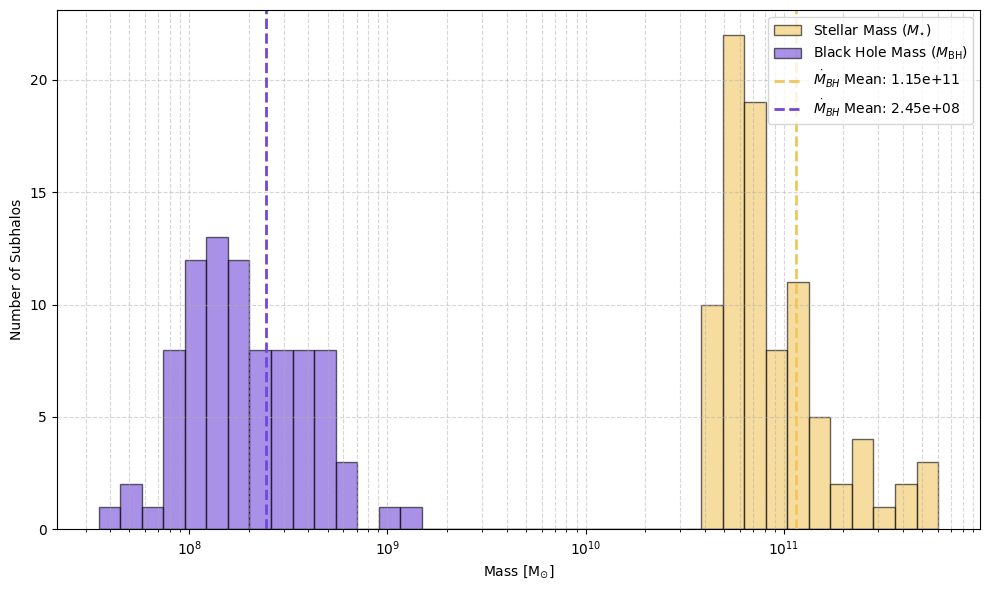

In [54]:
min_mass = min(clean_mstar.min(), clean_mbh.min())
max_mass = max(clean_mstar.max(), clean_mbh.max())
bins_overlap = np.logspace(np.log10(min_mass), np.log10(max_mass), 40)

plt.figure(figsize=(10, 6))
plt.hist(clean_mstar, bins=bins_overlap, color='#f0c65d', alpha=0.6, edgecolor='black', label='Stellar Mass ($M_{\star}$)')
plt.hist(clean_mbh, bins=bins_overlap, color='#7148d9', alpha=0.6, edgecolor='black', label='Black Hole Mass ($M_{\mathrm{BH}}$)')

plt.axvline(np.mean(clean_mstar), color='#f0c65d', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_mstar):.2e}")
plt.axvline(np.mean(clean_mbh), color='#7148d9', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_mbh):.2e}")

plt.xscale('log')
plt.xlabel('Mass [$\mathrm{M}_{\odot}$]')
plt.ylabel('Number of Subhalos')
plt.legend(loc='upper right')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("masses_overlapping.png", dpi=300)
plt.show()